### Notebook 3b — Synthetic Image Generation with RoentGen-v2
---
>Generate the synthetic chest X-rays used in scenarios 4 and 5 with RoentGen-v2 (text-to-image latent diffusion model for chest radiographs): 5,000 Pneumonia + 2,500 No Finding images. The model is used **zero-shot** (no fine-tuning), prompted with the age and sex of the real 5K patients. The notebook also runs screening checks; formal quality metrics (FID/KID, real-vs-synthetic detector, memorisation) are computed in Notebook 3c.

### 1. Configuration and Loading

**Requirements in Kaggle:** GPU accelerator on, **Internet on**, and a Kaggle Secret named `HF_TOKEN` (Add-ons → Secrets) holding a Hugging Face token of an account that has accepted the conditions of `stanfordmimi/RoentGen-v2`. The token is read from the secret and is never written in the code.

**Design decisions**

* **Zero-shot generation.** The model never sees NIH images, so the synthetic data derives from MIMIC-CXR (external knowledge, to be stated as a limitation). If the real-vs-synthetic detector in Notebook 3c shows a large domain gap, a light LoRA fine-tuning on `real_5k` is the natural ablation.
* **Prompts follow the model's training format:** `<AGE> year old <SEX>. <IMPRESSION>`. Age and sex are sampled from the real 5K patients of the same class, so the synthetic demographic profile mirrors the (matched) real one. Race is omitted because NIH does not record it. Ages are clipped to adults, since the model was trained on adults.
* **Impressions** are short MIMIC-style phrases, several per class to add variety. They are editable in section 2.
* **Generation settings** are the ones used by the model authors: 512×512, 75 steps, guidance 4.0.
* **Reproducibility:** one seed per image, so every image is identical regardless of batch size or restarts. Generation is **resumable** (existing PNGs are skipped).
* **Sanity filter only for degenerate outputs** (black, saturated or flat images are regenerated up to 3 times). Images are **not** filtered by any classifier score: selecting images that a chest X-ray classifier finds convincing would pre-select easy cases and bias the experiment.

In [1]:
import os, time, json, math, random
from pathlib import Path
from concurrent.futures import ThreadPoolExecutor
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
import torch, torch.nn.functional as F

SEED = 42
MODEL_ID = 'stanfordmimi/RoentGen-v2'
SIZE, STEPS, GUIDANCE = 512, 30, 4.0
BATCH = 8
USE_DPM_SOLVER = True
DTYPE = torch.float16
N_SYN = {'pos': 5000, 'neg': 2500}
RUN_CLASSES = ['pos']                       # <- cambiado respecto al valor por defecto
MAX_ATTEMPTS, MIN_STD, MIN_MEAN, MAX_MEAN = 3, 12, 20, 235
MIN_AGE, MAX_AGE = 18, 90
RUN_XRV = False                             # <- cambiado
MAX_IMAGES_THIS_RUN = None
RESUME_FROM = None

WORK = Path('/kaggle/working')
OUT_DIR = WORK / 'synthetic' / 'roentgen'
for sub in ('pneumonia', 'no_finding'):
    (OUT_DIR / sub).mkdir(parents=True, exist_ok=True)

DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
assert DEVICE == 'cuda', 'Enable a GPU accelerator (Settings -> Accelerator)'
print('GPU:', torch.cuda.get_device_name(0))

# --- Hugging Face token from Kaggle Secrets (never hard-code it) ---
try:
    from kaggle_secrets import UserSecretsClient
    HF_TOKEN = UserSecretsClient().get_secret('HF_TOKEN')
except Exception:
    HF_TOKEN = os.environ.get('HF_TOKEN')
assert HF_TOKEN, 'HF_TOKEN not found: add it in Add-ons -> Secrets and attach it to this notebook'

# --- Locate the splits exported by Notebook 2 ---
def find_splits(root='/kaggle/input', name='real_5k.csv', max_depth=6):
    for cur, dirs, files in os.walk(root):
        depth = cur[len(root):].count(os.sep)
        if name in files:
            return cur
        dirs[:] = [d for d in dirs if d != 'images'] if depth < max_depth else []
    return None

SPLITS_DIR = find_splits()
assert SPLITS_DIR, 'real_5k.csv not found: attach the splits (Dataset or Notebook 2 output) via + Add Input'
print('SPLITS_DIR =', SPLITS_DIR)

real_5k = pd.read_csv(f'{SPLITS_DIR}/real_5k.csv')
assert {'Patient Age', 'Patient Gender', 'label', 'path'} <= set(real_5k.columns)
print(f"real_5k: {int((real_5k.label == 1).sum())} positives | {int((real_5k.label == 0).sum())} negatives (used only for demographics and as visual reference)")

GPU: Tesla T4
SPLITS_DIR = /kaggle/input/notebooks/anafarr/02-cohort-definition-and-splits/splits
real_5k: 683 positives | 4317 negatives (used only for demographics and as visual reference)


### 2. Prompt Plan

Builds the full table of 7,500 images (prompt, demographics, seed, output path) **before** generating anything and saves it as `roentgen_plan.csv`. The first 2,500 positives are flagged `only_2500` (scenario 4); all 5,000 are used in scenario 5, together with the 2,500 negatives.

In [2]:
POS_IMPRESSIONS = ['Pneumonia.', 'Findings consistent with pneumonia.', 'Right lower lobe pneumonia.',
                   'Left lower lobe pneumonia.', 'Bilateral pneumonia.', 'Right middle lobe pneumonia.']
NEG_IMPRESSIONS = ['Normal chest radiograph.', 'No acute cardiopulmonary abnormality.', 'No acute cardiopulmonary process.']

rng = np.random.default_rng(SEED)
rows = []
for cls, label, base_seed, folder in [('pos', 1, 100_000, 'pneumonia'), ('neg', 0, 200_000, 'no_finding')]:
    ref = real_5k[real_5k.label == label]
    impressions = POS_IMPRESSIONS if label else NEG_IMPRESSIONS
    pick = ref.sample(N_SYN[cls], replace=N_SYN[cls] > len(ref), random_state=SEED + label)
    for i, (age, sex) in enumerate(zip(pick['Patient Age'], pick['Patient Gender'])):
        age = int(np.clip(age, MIN_AGE, MAX_AGE)); sex_txt = 'male' if sex == 'M' else 'female'
        imp = impressions[int(rng.integers(len(impressions)))]
        fn = f'roentgen_{cls}_{i:05d}.png'
        rows.append({'image': fn, 'path': str(OUT_DIR / folder / fn), 'cls': cls, 'label': label, 'index': i,
                     'gen_seed': base_seed + i, 'age': age, 'sex': sex_txt, 'impression': imp,
                     'prompt': f'{age} year old {sex_txt}. {imp}',
                     'subset': 'only_2500' if (label == 0 or i < 2500) else 'extra_pos'})
plan = pd.DataFrame(rows)
plan.to_csv(OUT_DIR / 'roentgen_plan.csv', index=False)

print(plan.groupby('cls').agg(n=('image', 'size'), age_mean=('age', 'mean'), male_pct=('sex', lambda s: 100 * (s == 'male').mean())).round(1))
print('\nExample prompts:'); print(plan.groupby('cls').head(3)[['cls', 'prompt', 'gen_seed']].to_string(index=False))

        n  age_mean  male_pct
cls                          
neg  2500      45.8      56.9
pos  5000      45.5      58.2

Example prompts:
cls                                                    prompt  gen_seed
pos                            22 year old female. Pneumonia.    100000
pos                    51 year old male. Bilateral pneumonia.    100001
pos            65 year old female. Left lower lobe pneumonia.    100002
neg              22 year old female. Normal chest radiograph.    200000
neg              27 year old female. Normal chest radiograph.    200001
neg 31 year old female. No acute cardiopulmonary abnormality.    200002


### 3. Load RoentGen-v2

Loaded in half precision without the Stable Diffusion safety checker (it can blank out medical images). Run the install cell once per session.

In [3]:
base = Path('/kaggle/input/notebooks/anafarr/03b-synthetic-image-generation-roentgen-v2')
items = sorted(base.rglob('*'))
print(len(items), 'items'); print(*items[:20], sep='\n')

0 items



In [4]:
if RESUME_FROM:
    import shutil
    cands = [p for p in Path('/kaggle/input').rglob('roentgen') if p.is_dir()]
    info = {str(p): len(list(p.rglob('*.png'))) for p in cands}
    print('roentgen folders found in /kaggle/input and their PNG count:', info)
    assert info and max(info.values()) > 0, ('no previous roentgen images found in the inputs: '
        'check + Add Input (03b output) and which version of that notebook is being used')
    best = Path(max(info, key=info.get))
    n_copied = 0
    for f in best.rglob('*'):
        if f.is_file() and f.name != 'roentgen_plan.csv' and not f.name.startswith('roentgen_manifest'):
            dst = OUT_DIR / f.relative_to(best); dst.parent.mkdir(parents=True, exist_ok=True)
            if not dst.exists():
                shutil.copy2(f, dst); n_copied += 1
    print(f'Resumed from {best}: {n_copied:,} files copied')
else:
    print('Fresh run (RESUME_FROM is None)')

Fresh run (RESUME_FROM is None)


In [5]:
%pip install -q -U diffusers transformers accelerate

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.6/12.6 MB 92.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 394.3/394.3 kB 17.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 846.4/846.4 kB 21.9 MB/s eta 0:00:00
Note: you may need to restart the kernel to use updated packages.


In [6]:
from diffusers import StableDiffusionPipeline

pipe = StableDiffusionPipeline.from_pretrained(MODEL_ID, torch_dtype=DTYPE, safety_checker=None,
                                               requires_safety_checker=False, token=HF_TOKEN)
pipe = pipe.to(DEVICE); pipe.enable_attention_slicing(); pipe.set_progress_bar_config(disable=True)
if USE_DPM_SOLVER:
    from diffusers import DPMSolverMultistepScheduler
    pipe.scheduler = DPMSolverMultistepScheduler.from_config(pipe.scheduler.config)
print('RoentGen-v2 loaded | scheduler:', type(pipe.scheduler).__name__,
      '| prediction_type:', getattr(pipe.scheduler.config, 'prediction_type', None))

/usr/local/lib/python3.13/dist-packages/diffusers/utils/deprecation_utils.py:23: FutureWarning: `torch_dtype` is deprecated and will be removed in version 1.0.0. Please use `dtype` instead.
  deprecate("torch_dtype", "1.0.0", _TORCH_DTYPE_DEPRECATION_MESSAGE)


model_index.json:   0%|          | 0.00/648 [00:00<?, ?B/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 14 files:   0%|          | 0/14 [00:00<?, ?it/s]

Loading pipeline components...:   0%|          | 0/6 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/372 [00:00<?, ?it/s]

RoentGen-v2 loaded | scheduler: DPMSolverMultistepScheduler | prediction_type: epsilon


### 4. Generation Functions and Timing Test

`run_batch` generates a batch with one seeded generator per image, converts to 8-bit grayscale and regenerates (with a new seed) any image that fails the degenerate-image filter. After `MAX_ATTEMPTS` the last result is kept but flagged `degenerate` in the manifest. Every image written is logged in `roentgen_log.jsonl`.

The timing test generates and **keeps** the first batch, and extrapolates the total time. **Read it before launching the full run.** If most images come out black, switch `DTYPE` to `torch.float32`. If the estimate does not fit in one session, either run one class per session (`RUN_CLASSES = ['pos']`, then `['neg']`; each writes its own manifest) or set `USE_DPM_SOLVER = True` with `STEPS = 30`.

4.9 s/image  ->  about 6.8 h for 5,000 images
Degenerate images in this batch: 0 | extra attempts: 0


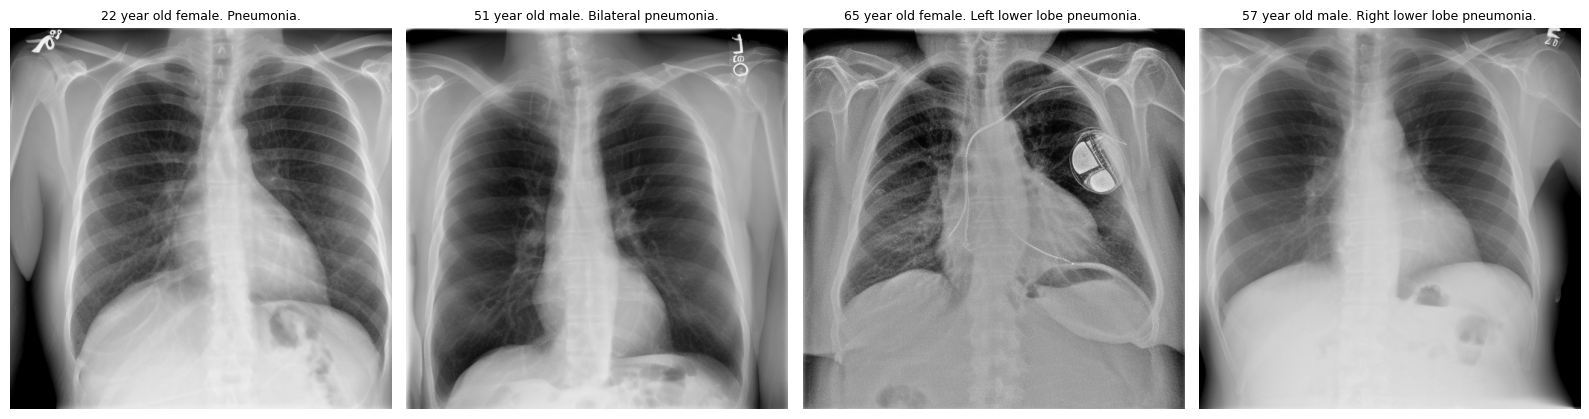

In [7]:
LOG = OUT_DIR / 'roentgen_log.jsonl'

def is_degenerate(a):
    return a.std() < MIN_STD or a.mean() < MIN_MEAN or a.mean() > MAX_MEAN

@torch.no_grad()
def run_batch(rows):
    results, pending = {}, list(range(len(rows)))
    for attempt in range(MAX_ATTEMPTS):
        if not pending:
            break
        sub = rows.iloc[pending]
        gens = [torch.Generator(device=DEVICE).manual_seed(int(s) + attempt * 10_000_000) for s in sub['gen_seed']]
        imgs = pipe(list(sub['prompt']), num_inference_steps=STEPS, guidance_scale=GUIDANCE,
                    height=SIZE, width=SIZE, generator=gens).images
        still = []
        for j, im in zip(pending, imgs):
            a = np.asarray(im.convert('L'), dtype=np.uint8)
            if is_degenerate(a) and attempt < MAX_ATTEMPTS - 1:
                still.append(j)
            else:
                results[j] = (a, attempt + 1, bool(is_degenerate(a)))
        pending = still
    return results

def process(batch):
    res = run_batch(batch)
    with open(LOG, 'a') as f:
        for j, (a, att, bad) in res.items():
            r = batch.iloc[j]
            Image.fromarray(a, 'L').save(r['path'])
            f.write(json.dumps({'image': r['image'], 'attempts': att, 'degenerate': bad}) + '\n')
    return res

first = plan[plan.cls == RUN_CLASSES[0]].iloc[:BATCH]
first = first[~first.path.map(os.path.exists)]
if len(first):
    t0 = time.time(); res = process(first)
    if DEVICE == 'cuda': torch.cuda.synchronize()
    per_img = (time.time() - t0) / len(first)
    print(f'{per_img:.1f} s/image  ->  about {sum(N_SYN[c] for c in RUN_CLASSES) * per_img / 3600:.1f} h for {sum(N_SYN[c] for c in RUN_CLASSES):,} images')
    print('Degenerate images in this batch:', sum(v[2] for v in res.values()), '| extra attempts:', sum(v[1] - 1 for v in res.values()))
fig, ax = plt.subplots(1, 4, figsize=(16, 4.3))
for a_, (_, r) in zip(ax, plan[plan.cls == RUN_CLASSES[0]].iloc[:4].iterrows()):
    a_.imshow(Image.open(r['path']), cmap='gray'); a_.set_title(r['prompt'], fontsize=9); a_.axis('off')
plt.tight_layout(); plt.show()

### 5. Full Generation

Resumable: it only generates images whose PNG does not exist yet, so after an interruption you just run the cell again. It prints the elapsed time and an estimate of the time left every 25 batches. If Kaggle cuts the session, the images already generated are kept in `/kaggle/working`.

In [8]:
todo = plan[plan.cls.isin(RUN_CLASSES) & ~plan.path.map(os.path.exists)]
print(f'{len(todo):,} images to generate ({int(plan.path.map(os.path.exists).sum()):,} already on disk)')
t0, done = time.time(), 0
for i in range(0, len(todo), BATCH):
    batch = todo.iloc[i:i + BATCH]
    process(batch); done += len(batch)
    if (i // BATCH) % 25 == 0 or done == len(todo):
        el = time.time() - t0
        print(f'{done:,}/{len(todo):,} | {el / 60:.0f} min elapsed | about {(len(todo) - done) * el / done / 60:.0f} min left')

4,992 images to generate (8 already on disk)
8/4,992 | 1 min elapsed | about 424 min left
208/4,992 | 18 min elapsed | about 411 min left
408/4,992 | 35 min elapsed | about 394 min left
608/4,992 | 52 min elapsed | about 376 min left
808/4,992 | 69 min elapsed | about 359 min left
1,008/4,992 | 87 min elapsed | about 342 min left
1,208/4,992 | 104 min elapsed | about 325 min left
1,408/4,992 | 121 min elapsed | about 308 min left
1,608/4,992 | 138 min elapsed | about 291 min left
1,808/4,992 | 155 min elapsed | about 274 min left
2,008/4,992 | 172 min elapsed | about 256 min left
2,208/4,992 | 190 min elapsed | about 239 min left
2,408/4,992 | 207 min elapsed | about 222 min left
2,608/4,992 | 224 min elapsed | about 205 min left
2,808/4,992 | 241 min elapsed | about 188 min left
3,008/4,992 | 259 min elapsed | about 171 min left
3,208/4,992 | 276 min elapsed | about 153 min left
3,408/4,992 | 293 min elapsed | about 136 min left
3,608/4,992 | 310 min elapsed | about 119 min left
3,808

### 6. Manifest

Joins the plan with the generation log. `attempts` > 1 means the first seed produced a degenerate image; `degenerate = True` means the image still failed the filter after the last attempt (exclude those downstream).

In [9]:
log = (pd.read_json(LOG, lines=True).drop_duplicates('image', keep='last')
       if LOG.exists() else pd.DataFrame(columns=['image', 'attempts', 'degenerate']))
man = plan.merge(log, on='image', how='left')
man = man[man.path.map(os.path.exists) & man.cls.isin(RUN_CLASSES)].copy()
man['source'], man['generator'], man['img_size'] = 'synthetic', 'roentgen_v2', SIZE
man['attempts'] = man['attempts'].fillna(1).astype(int); man['degenerate'] = man['degenerate'].fillna(False).astype(bool)
tag = '' if set(RUN_CLASSES) == {'pos', 'neg'} else '_' + '_'.join(RUN_CLASSES)     # per-class manifest if run separately
man.to_csv(OUT_DIR / f'roentgen_manifest{tag}.csv', index=False)

print(f'{len(man):,} images in the manifest (planned {int(plan.cls.isin(RUN_CLASSES).sum()):,})')
print(man.groupby(['label', 'subset']).size().rename('images'))
print('\nDegenerate after all attempts:', int(man.degenerate.sum()), '| needed a retry:', int((man.attempts > 1).sum()))

5,000 images in the manifest (planned 5,000)
label  subset   
1      extra_pos    2500
       only_2500    2500
Name: images, dtype: int64

Degenerate after all attempts: 0 | needed a retry: 1


/tmp/ipykernel_23/1641101758.py:6: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  man['attempts'] = man['attempts'].fillna(1).astype(int); man['degenerate'] = man['degenerate'].fillna(False).astype(bool)


### 7. Visual Check and Intensity Statistics

First 8 synthetic images of each class (with their prompt) next to 8 random real images of the same class. The statistics compare, on 300 images per group at 128×128, the mean intensity, the within-image contrast (std) and the spread of mean intensities across images (a diversity proxy). Large differences are a trivial shortcut for the classifier (source = class) and will be quantified in Notebook 3c.

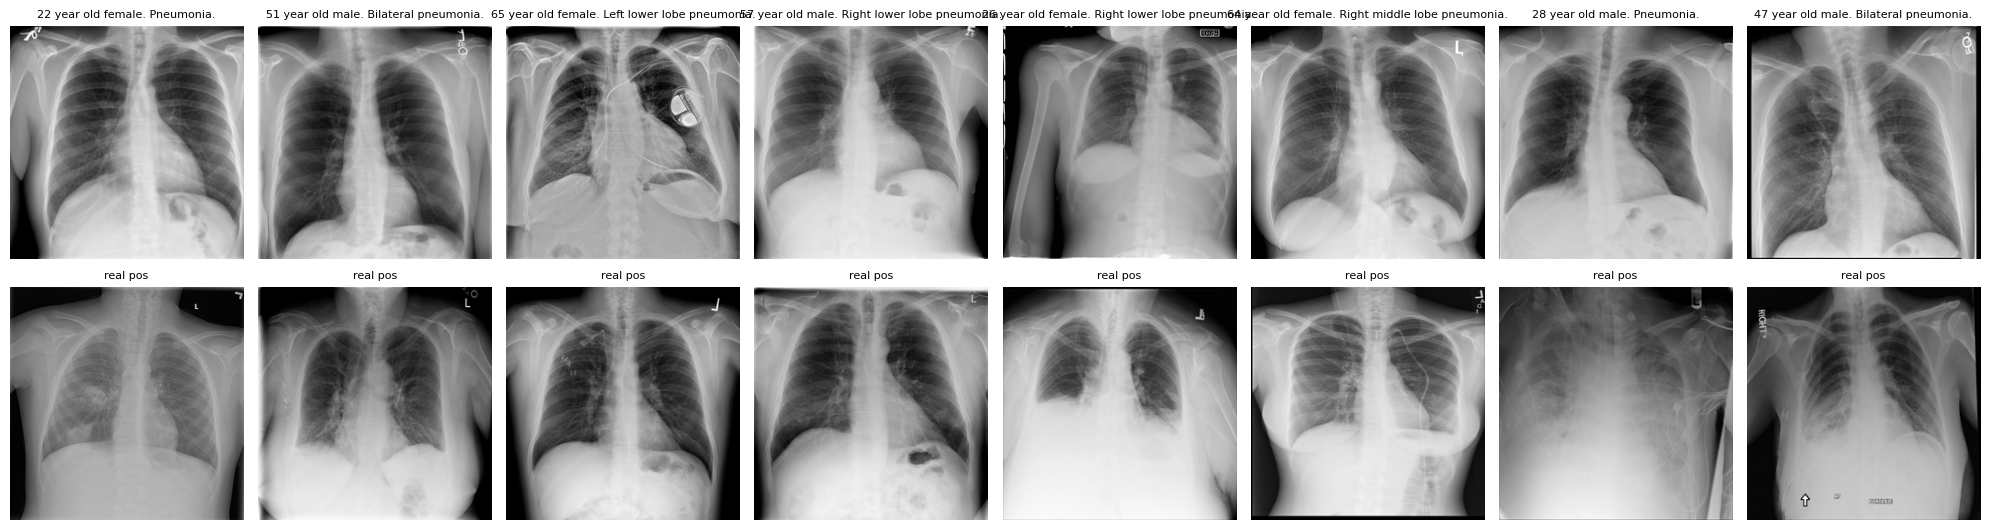

               mean intensity  contrast (within-image std)  \
pos real           125.300003                    59.299999   
    synthetic      133.500000                    53.799999   

               spread of image means  
pos real                   20.700001  
    synthetic              11.500000  


In [10]:
def load_gray(path, size):
    im = Image.open(path).convert('L')
    return np.asarray(im.resize((size, size), Image.Resampling.LANCZOS), dtype=np.uint8)

def load_many(paths, size, workers=8):
    with ThreadPoolExecutor(workers) as ex:
        return np.stack(list(ex.map(lambda p: load_gray(p, size), list(paths))))

CLASSES = [(c, l) for c, l in [('pos', 1), ('neg', 0)] if (man.cls == c).any()]
fig, ax = plt.subplots(2 * len(CLASSES), 8, figsize=(20, 5.5 * len(CLASSES)), squeeze=False)
for r, (cls, lab) in enumerate(CLASSES):
    syn = man[man.cls == cls].head(8); real = real_5k[real_5k.label == lab].sample(8, random_state=SEED)
    for k, ((_, s), p) in enumerate(zip(syn.iterrows(), real['path'])):
        ax[2 * r, k].imshow(load_gray(s['path'], 256), cmap='gray'); ax[2 * r, k].set_title(s['prompt'], fontsize=8)
        ax[2 * r + 1, k].imshow(load_gray(p, 256), cmap='gray'); ax[2 * r + 1, k].set_title(f'real {cls}', fontsize=8)
for a in ax.ravel(): a.axis('off')
plt.tight_layout(); plt.show()

stats = {}
for cls, lab in CLASSES:
    for src, paths in [('real', real_5k[real_5k.label == lab].sample(300, random_state=SEED)['path']),
                       ('synthetic', man[man.cls == cls].sample(min(300, int((man.cls == cls).sum())), random_state=SEED)['path'])]:
        a = load_many(paths, 128).astype(np.float32)
        stats[(cls, src)] = {'mean intensity': a.mean(), 'contrast (within-image std)': a.std(axis=(1, 2)).mean(),
                             'spread of image means': a.mean(axis=(1, 2)).std()}
print(pd.DataFrame(stats).T.round(1))

### 8. Export

Everything needed downstream is in `/kaggle/working/synthetic/roentgen/`: the PNGs (512×512, 8-bit grayscale), `roentgen_manifest.csv`, `roentgen_plan.csv` and the generation log. Commit the notebook ("Save Version") and publish the output as a private Kaggle Dataset (e.g. `synthetic-roentgen`) to use it in Notebooks 3c and 4+.

In [11]:
total = sum(f.stat().st_size for f in OUT_DIR.rglob('*') if f.is_file()) / 1e6
print(f'Synthetic output: {len(man):,} images, {total:.0f} MB in {OUT_DIR}')

Synthetic output: 5,000 images, 626 MB in /kaggle/working/synthetic/roentgen
